🧠 **Xception Transfer Learning - Image Classification**
- This notebook demonstrates how to use Xception with transfer learning on a small custom dataset.

In [1]:
# Imports
import tensorflow as tf
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import os

Dataset Link :- https://drive.google.com/file/d/1TCU1nqgIe1R_dW6LTkRxlufHlCCazyJl/view?usp=sharing

In [2]:
import gdown

# Google Drive file ID
file_id = "1TCU1nqgIe1R_dW6LTkRxlufHlCCazyJl"
# Download destination filename
output = "myfile.zip"

# Download the file
gdown.download(f"https://drive.google.com/uc?id={file_id}", output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1TCU1nqgIe1R_dW6LTkRxlufHlCCazyJl
From (redirected): https://drive.google.com/uc?id=1TCU1nqgIe1R_dW6LTkRxlufHlCCazyJl&confirm=t&uuid=c61c68ad-4e8b-4df5-bda8-829d9d4f9395
To: /content/myfile.zip
100%|██████████| 63.9M/63.9M [00:01<00:00, 39.1MB/s]


'myfile.zip'

In [3]:
import zipfile

with zipfile.ZipFile("myfile.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [4]:
# 📁 2. Define paths (update with your dataset path)
train_dir = "/content/dataset/train"
val_dir = "/content/dataset/valid"
img_size = 299
batch_size = 32


In [5]:
# data generation
train_datagen=ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)
val_datagen=ImageDataGenerator(preprocessing_function=preprocess_input)

train_data=train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical')
val_data=val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical')

Found 1275 images belonging to 2 classes.
Found 364 images belonging to 2 classes.


In [6]:
base_model=Xception(weights='imagenet',include_top=False, input_shape=(img_size, img_size, 3))
base_model.trainable=False

In [7]:
base_model.summary()

Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 149, 149,  │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 149, 149,  │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 149, 149,  │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 147, 147,  │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 147, 147,  │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 147, 147,  │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 147, 147,  │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 147, 147,  │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 147, 147,  │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 147, 147,  │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 147, 147,  │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 74, 74,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 74, 74,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 74, 74,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 74, 74,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 74, 74,    │          0 │ add[0][0]       

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 20,861,480 (79.58 MB)

In [8]:
x=base_model.output
x=GlobalAveragePooling2D()(x)
x=Dropout(0.5)(x)
pred=Dense(train_data.num_classes, activation='softmax')(x)

model= Model(inputs=base_model.input, outputs=pred)

In [9]:

# compile and train
model.compile(optimizer=Adam(learning_rate=1e-4), loss='categorical_crossentropy', metrics=['accuracy'])

history=model.fit(train_data, batch_size=batch_size, epochs=10, verbose=1, validation_data=val_data)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.5624 - loss: 0.6868 - val_accuracy: 0.8407 - val_loss: 0.5641
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 35s 873ms/step - accuracy: 0.8039 - loss: 0.5165 - val_accuracy: 0.9066 - val_loss: 0.4410
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 904ms/step - accuracy: 0.8502 - loss: 0.4455 - val_accuracy: 0.9313 - val_loss: 0.3658
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 36s 883ms/step - accuracy: 0.8729 - loss: 0.3835 - val_accuracy: 0.9176 - val_loss: 0.3182
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 35s 876ms/step - accuracy: 0.8863 - loss: 0.3469 - val_accuracy: 0.9148 - val_loss: 0.2852
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 35s 872ms/step - accuracy: 0.8847 - loss: 0.3145 - val_accuracy: 0.9148 - val_loss: 0.2631
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 34s 856ms/step - accuracy: 0.8988 - loss: 0.2980 - val_accuracy: 0.9176 - val_loss: 0.2455
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 35s 865ms/step - accuracy: 0.9090 - loss: 0.2752 - val_accura

In [10]:
# 🔓 8. Fine-tune Unfreeze and fine-tune (optional)
# base_model.trainable = True
# model.compile(optimizer=Adam(learning_rate=1e-5),
#               loss='categorical_crossentropy',
#               metrics=['accuracy'])

# fine_tune_history = model.fit(
#     train_generator,
#     epochs=5,
#     validation_data=val_generator
# )

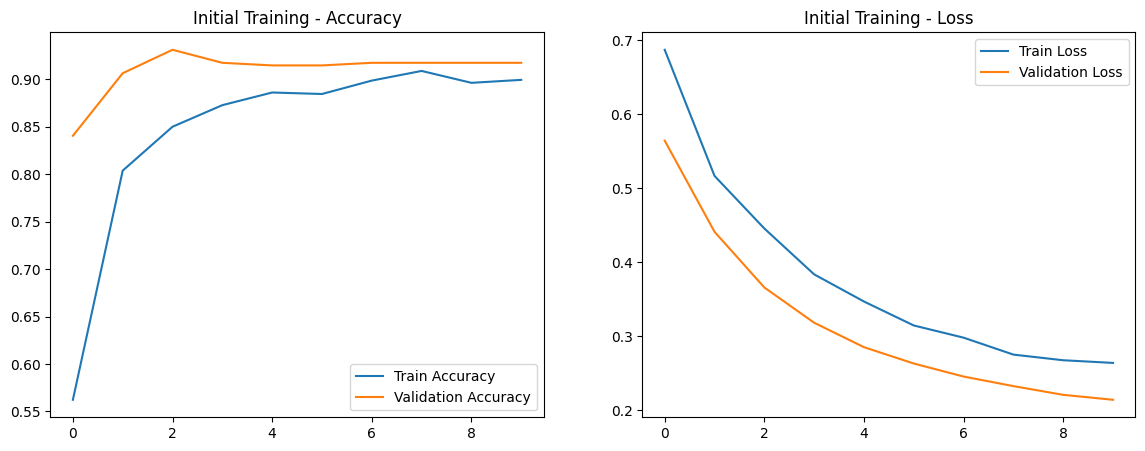

In [11]:
# 📊 9. Plot training history
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(len(acc))

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Train Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title(f'{title} - Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Train Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title(f'{title} - Loss')
    plt.legend()

    plt.show()

plot_history(history, "Initial Training")

In [12]:
model.save('xception_transfer_learning_model.keras')

In [13]:
from tensorflow.keras.models import load_model

model = load_model("xception_transfer_learning_model.keras")

In [14]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

def predict_image(model, image_path):
    img = load_img(image_path, target_size=(299, 299))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    predictions = model.predict(img_array)
    predicted_class = np.argmax(predictions, axis=1)
    class_indices = {v: k for k, v in train_data.class_indices.items()}
    return class_indices[predicted_class[0]]



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Predicted Label: daisy


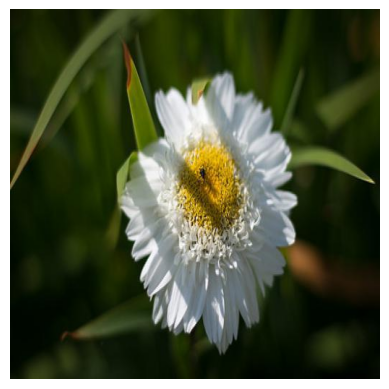

In [17]:
# Example usage
image_path = "/content/dataset/test/daisy/14613443462_d4ed356201_jpg.rf.76462b3f0cb5ca5a0b4b7c9894feb91c.jpg"  # Update path accordingly
predicted_label = predict_image(model, image_path)
print("Predicted Label:", predicted_label)
plt.imshow(load_img(image_path))
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Label: dandelion


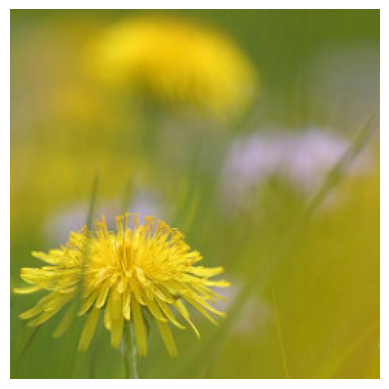

In [18]:
# Example usage
image_path = "/content/dataset/test/dandelion/14060367700_fe87e99b6a_m_jpg.rf.eaf8222cde370b2ebb4d6a1378ec07b1.jpg"  # Update path accordingly
predicted_label = predict_image(model, image_path)
print("Predicted Label:", predicted_label)
plt.imshow(load_img(image_path))
plt.axis('off')
plt.show()